# Classical Computer Vision Pipeline for Imagenette Classification
**Course:** Machine Vision (Fall 2026) — Amirkabir University of Technology (Tehran Polytechnic)  
**Instructor:** Dr. Shariatmadar Mortazavi  
**Student:** Kasra Adimi (`40123006`)

---

## Project Overview
This notebook implements an end-to-end **classical computer vision** classification pipeline on the 10-class **Imagenette2** dataset without using any deep neural networks (CNNs, Transformers, etc.). The workflow covers:
1. Reproducible environment setup and hardware benchmarking.
2. Strict train/validation isolation and exploratory data analysis (EDA).
3. Multi-modal classical feature extraction (Color, Shape/Edge, Texture, Frequency, and Local Keypoints via BoVW/VLAD).
4. Feature fusion, normalization, and a systematic Ablation Study.
5. Classical ML classifier optimization, ensembling, and targeted off-diagonal error analysis.

## 1. Environment Setup, Reproducibility & Hardware Logging
In this section, we import the required libraries, configure project directories (`dataset` and `cache`), and lock the global random seed (`SEED = 42`) across Python and NumPy to guarantee reproducible results. We also log the system's hardware specifications (OS, CPU cores, and RAM) for runtime benchmarking in the final report.

In [1]:
import os
import random
import platform
import time
from pathlib import Path

import cv2
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# 1. Reproducibility (Global Random Seed)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# 2. Project Paths
BASE_DIR = Path(".")
DATASET_DIR = BASE_DIR / "dataset" / "imagenette2"
CACHE_DIR = BASE_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# 3. Log Hardware & Environment Specs (Required for Report)
print("=== Hardware & Environment Specifications ===")
print(f"OS: {platform.system()} {platform.release()}")
print(f"Python: {platform.python_version()}")
print(f"CPU: {platform.processor() or platform.machine()} | Physical cores: {psutil.cpu_count(logical=False)}, Logical cores: {psutil.cpu_count(logical=True)}")
print(f"RAM: {psutil.virtual_memory().total / (1024**3):.2f} GB")

=== Hardware & Environment Specifications ===
OS: Linux 7.0.0-43-generic
Python: 3.12.3
CPU: x86_64 | Physical cores: 4, Logical cores: 8
RAM: 15.32 GB


## 2. Dataset Loading & Strict Train/Validation Isolation
Here, we map the 10 ImageNet WordNet IDs (`wnid`) to their corresponding human-readable class labels and build structured DataFrames for the default `train` and `val` splits.

> **Data Leakage Prevention Policy:** The `val` split is strictly quarantined and reserved exclusively for final model evaluation. All exploratory analysis, feature scaling, visual vocabulary clustering (K-Means), and hyperparameter tuning will be performed solely on the `train` split.

In [3]:
# Mapping WordNet IDs to human-readable class names
CLASS_MAP = {
    "n01440764": "Tench",
    "n02102040": "English Springer",
    "n02979186": "Cassette Player",
    "n03000684": "Chain Saw",
    "n03028079": "Church",
    "n03394916": "French Horn",
    "n03417042": "Garbage Truck",
    "n03425413": "Gas Pump",
    "n03445777": "Golf Ball",
    "n03888257": "Parachute",
}

# Sorted label encoding (0 to 9) for consistency
WNID_TO_IDX = {wnid: idx for idx, wnid in enumerate(sorted(CLASS_MAP.keys()))}
IDX_TO_NAME = {idx: CLASS_MAP[wnid] for wnid, idx in WNID_TO_IDX.items()}

def build_split_df(split_dir: Path) -> pd.DataFrame:
    records = []
    for wnid, label_idx in WNID_TO_IDX.items():
        class_dir = split_dir / wnid
        if not class_dir.exists():
            raise FileNotFoundError(f"Missing directory: {class_dir}")
        for img_path in sorted(class_dir.glob("*")):
            if img_path.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                records.append({
                    "path": str(img_path),
                    "wnid": wnid,
                    "label": label_idx,
                    "class_name": CLASS_MAP[wnid]
                })
    return pd.DataFrame(records)

train_df = build_split_df(DATASET_DIR / "train")
val_df = build_split_df(DATASET_DIR / "val")

print(f"Train samples: {len(train_df)}")
print(f"Val samples:   {len(val_df)}")
train_df.head()

Train samples: 9469
Val samples:   3925


,path,wnid,label,class_name
0,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
1,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
2,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
3,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench
4,dataset/imagenette2/train/n01440764/ILSVRC2012...,n01440764,0,Tench


## 3. Exploratory Data Analysis (EDA)
Before designing the preprocessing and feature extraction pipeline, we inspect the `train` split to identify potential edge cases and guide our architectural choices:
- **Class Balance:** Verify sample counts across all 10 classes in both splits.
- **Channel Consistency:** Detect grayscale (1-channel) or RGBA (4-channel) images that must be standardized to 3-channel RGB before extracting color descriptors.
- **Resolution & Aspect Ratio Distribution:** Analyze image dimensions to select appropriate resizing strategies for global descriptors (e.g., HOG) versus local keypoint detectors (e.g., SIFT/ORB).

In [4]:
# 1. Class distribution comparison
dist_df = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Val": val_df["class_name"].value_counts()
})
display(dist_df)

# 2. Inspect image shapes, channels, and aspect ratios on Train split
heights, widths, channels = [], [], []
corrupted_files = []

for path in tqdm(train_df["path"], desc="Inspecting Train Images"):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        corrupted_files.append(path)
        continue
    if img.ndim == 2:
        h, w = img.shape
        c = 1
    else:
        h, w, c = img.shape
    heights.append(h)
    widths.append(w)
    channels.append(c)

eda_stats = pd.DataFrame({
    "height": heights,
    "width": widths,
    "channels": channels,
    "aspect_ratio": np.array(widths) / np.array(heights)
})

print(f"\nCorrupted images: {len(corrupted_files)}")
print("Channel distribution:\n", eda_stats["channels"].value_counts())
print("\nResolution & Aspect Ratio Summary:")
display(eda_stats[["width", "height", "aspect_ratio"]].describe().round(2))

,Train,Val
class_name,,
Cassette Player,993,357
Chain Saw,858,386
Church,941,409
English Springer,955,395
French Horn,956,394
Garbage Truck,961,389
Gas Pump,931,419
Golf Ball,951,399
Parachute,960,390


Inspecting Train Images:   0%|          | 0/9469 [00:00<?, ?it/s]


Corrupted images: 0
Channel distribution:
 channels
3    9296
1     173
Name: count, dtype: int64

Resolution & Aspect Ratio Summary:


,width,height,aspect_ratio
count,9469.00,9469.00,9469.00
mean,471.60,407.77,1.22
std,228.98,201.61,0.35
min,50.00,27.00,0.23
25%,375.00,333.00,0.95
50%,500.00,375.00,1.33
75%,500.00,500.00,1.40
max,4288.00,4368.00,5.02


## 4. Visual Inspection of Class Samples
To build domain intuition for classical feature engineering, we visualize one representative image from each of the 10 classes along with its native resolution. Observing dominant colors, geometric structures, surface textures, and background clutter helps prioritize which feature families will be most discriminative.

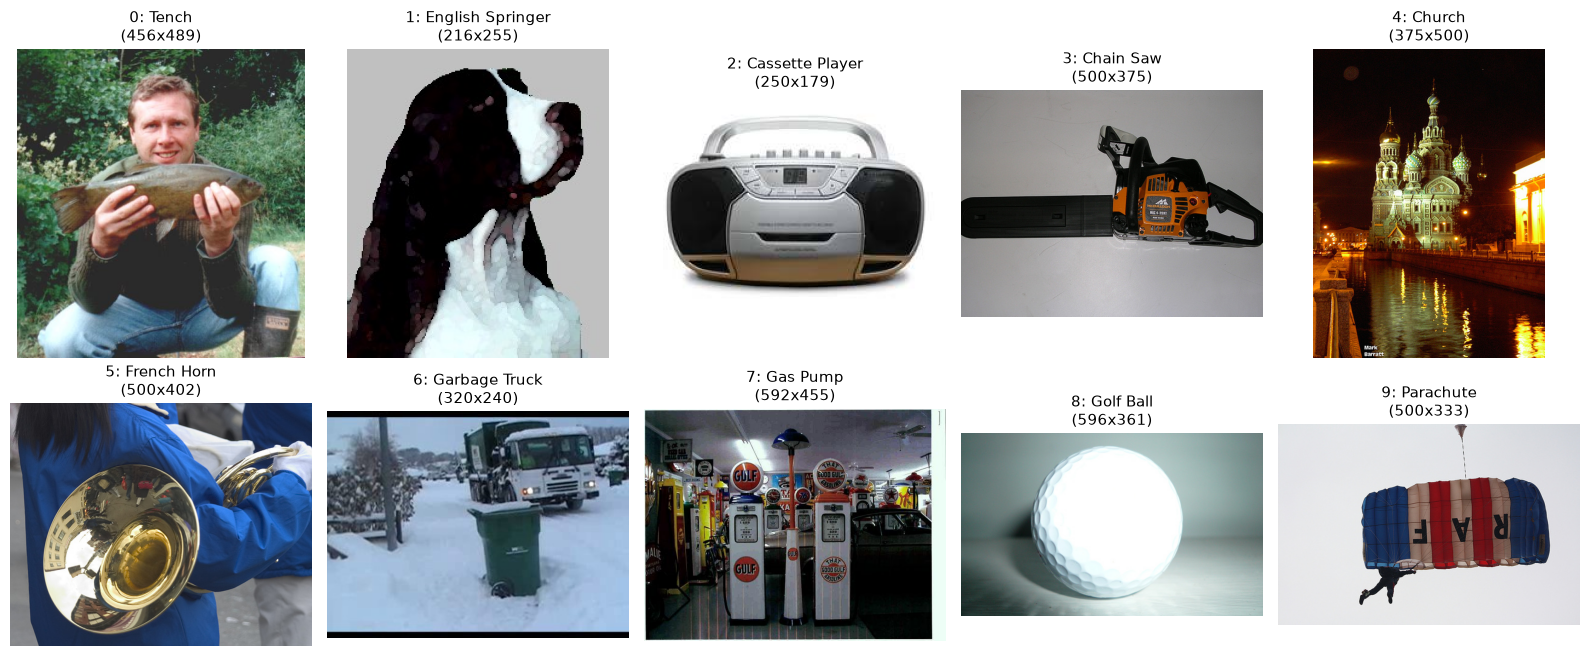

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.ravel()

for idx in range(10):
    sample_row = train_df[train_df["label"] == idx].sample(1, random_state=SEED).iloc[0]
    img_bgr = cv2.imread(sample_row["path"])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(f"{idx}: {sample_row['class_name']}\n({img_rgb.shape[1]}x{img_rgb.shape[0]})", fontsize=11)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

## 5. Preprocessing Utilities & Stratified K-Fold Setup
Based on our EDA findings (173 grayscale images and resolutions ranging from `50×27` to `4288×4368`), we define a **dual-resizing preprocessing strategy**:
- **Global Path (`128×128` RGB):** Standardizes spatial dimensions for fixed-length descriptors (Color grids, HOG, LBP, GLCM, FFT) while enforcing 3-channel RGB loading (`cv2.IMREAD_COLOR`).
- **Local Path (Aspect-Ratio Preserving, max side `320px`):** Preserves object geometry for keypoint detectors (RootSIFT in Phase 2B) without excessive memory overhead.

We also assign deterministic **Stratified 5-Fold Cross-Validation** indices on `train_df` so all ablation studies and hyperparameter tuning share identical splits.

In [6]:
from sklearn.model_selection import StratifiedKFold

# Preprocessing constants
GLOBAL_SIZE = (128, 128)
LOCAL_MAX_SIDE = 320
N_FOLDS = 5

def load_image_rgb(path: str) -> np.ndarray:
    """Loads any image (including 1-channel grayscale) strictly as 3-channel RGB."""
    img_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise ValueError(f"Failed to read image: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def resize_for_global(img_rgb: np.ndarray, size=GLOBAL_SIZE) -> np.ndarray:
    """Resizes image to fixed (W, H) for global descriptors."""
    interp = cv2.INTER_AREA if (img_rgb.shape[0] > size[1] or img_rgb.shape[1] > size[0]) else cv2.INTER_CUBIC
    return cv2.resize(img_rgb, size, interpolation=interp)

def resize_for_local(img_rgb: np.ndarray, max_side=LOCAL_MAX_SIDE) -> np.ndarray:
    """Resizes image preserving aspect ratio so the longest side <= max_side."""
    h, w = img_rgb.shape[:2]
    longest = max(h, w)
    if longest <= max_side:
        return img_rgb
    scale = max_side / longest
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    return cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)

# Assign deterministic Stratified 5-Fold indices on train_df
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df["fold"] = -1
for fold_idx, (_, val_idx) in enumerate(skf.split(train_df, train_df["label"])):
    train_df.loc[val_idx, "fold"] = fold_idx

print("Stratified 5-Fold distribution on train_df:")
display(pd.crosstab(train_df["fold"], train_df["label"]))

Stratified 5-Fold distribution on train_df:


label,0,1,2,3,4,5,6,7,8,9
fold,,,,,,,,,,
0,193,191,199,171,188,192,192,186,190,192
1,193,191,198,172,188,191,193,186,190,192
2,193,191,198,172,188,191,192,187,190,192
3,192,191,199,172,188,191,192,186,191,192
4,192,191,199,171,189,191,192,186,190,192


## 6. Classical Global Feature Extractors
We implement four distinct classical feature families so we can evaluate their individual and combined contributions in the upcoming Ablation Study:
1. **Color (`338` dims):** Global 3D HSV histogram (`8×4×4`), spatial `2×2` grid marginal histograms in HSV and CIELAB spaces, and color moments (mean, std, skewness).
2. **Shape & Edge (`1,784` dims):** HOG descriptors (`16×16` cells, `2×2` blocks, `9` orientations), spatial `2×2` Canny edge densities, Sobel orientation histogram, and log-transformed Hu Moments.
3. **Texture (`74` dims):** Multi-radius rotation-invariant Uniform LBP (`(P=8, R=1)`, `(16, 2)`, `(24, 3)`) and multi-distance GLCM statistics (contrast, dissimilarity, homogeneity, energy, correlation).
4. **Frequency (`40` dims):** Windowed 2D FFT log-magnitude spectrum summarized via 16 concentric radial frequency rings (mean & std) and 8 angular orientation wedges.

In [7]:
from scipy.stats import skew
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Precompute 2D Hann window and polar coordinate grids for 128x128 FFT
_H, _W = GLOBAL_SIZE[1], GLOBAL_SIZE[0]
_HANN_2D = np.outer(np.hanning(_H), np.hanning(_W)).astype(np.float32)
_Y, _X = np.ogrid[:_H, :_W]
_CY, _CX = _H // 2, _W // 2
_RADIUS_MAP = np.sqrt((_X - _CX)**2 + (_Y - _CY)**2)
_ANGLE_MAP = (np.arctan2(_Y - _CY, _X - _CX) + np.pi) % np.pi  # [0, pi) due to FFT symmetry
_RADIAL_BINS = np.linspace(0, np.sqrt(_CX**2 + _CY**2) + 1e-5, 17)
_ANGLE_BINS = np.linspace(0, np.pi + 1e-5, 9)


def extract_color_features(img_rgb: np.ndarray) -> np.ndarray:
    """Extracts 338-dim Color feature vector (HSV + Lab)."""
    img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    feats = []

    # 1. Global 3D HSV histogram (8x4x4 = 128)
    hist_3d = cv2.calcHist([img_hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
    hist_3d /= (hist_3d.sum() + 1e-7)
    feats.append(hist_3d)

    # 2. Spatial 2x2 grid 1D histograms in HSV & Lab (4 * 6 * 8 = 192)
    h, w = img_rgb.shape[:2]
    h_mid, w_mid = h // 2, w // 2
    slices = [(slice(0, h_mid), slice(0, w_mid)), (slice(0, h_mid), slice(w_mid, w)),
              (slice(h_mid, h), slice(0, w_mid)), (slice(h_mid, h), slice(w_mid, w))]
    
    for rs, cs in slices:
        hsv_q = img_hsv[rs, cs]
        lab_q = img_lab[rs, cs]
        for ch, max_val in [(0, 180), (1, 256), (2, 256)]:
            h1 = cv2.calcHist([hsv_q], [ch], None, [8], [0, max_val]).flatten()
            feats.append(h1 / (h1.sum() + 1e-7))
        for ch in range(3):
            h1 = cv2.calcHist([lab_q], [ch], None, [8], [0, 256]).flatten()
            feats.append(h1 / (h1.sum() + 1e-7))

    # 3. Color Moments (mean, std, skewness) for HSV & Lab (6 * 3 = 18)
    for space in (img_hsv, img_lab):
        for ch in range(3):
            vals = space[:, :, ch].astype(np.float32).ravel()
            m = vals.mean()
            s = vals.std()
            sk = float(skew(vals)) if s > 1e-5 else 0.0
            feats.append(np.array([m, s, sk], dtype=np.float32))

    return np.nan_to_num(np.concatenate(feats).astype(np.float32))


def extract_shape_features(img_gray: np.ndarray) -> np.ndarray:
    """Extracts 1,784-dim Shape & Edge feature vector (HOG + Canny + Sobel + Hu)."""
    # 1. HOG (7x7 blocks * 2x2 cells * 9 bins = 1764)
    hog_vec = hog(
        img_gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    ).astype(np.float32)

    # 2. Canny edge density (global + 2x2 grid = 5)
    edges = cv2.Canny(img_gray, 100, 200) > 0
    h, w = img_gray.shape
    h_mid, w_mid = h // 2, w // 2
    canny_feats = np.array([
        edges.mean(),
        edges[:h_mid, :w_mid].mean(),
        edges[:h_mid, w_mid:].mean(),
        edges[h_mid:, :w_mid].mean(),
        edges[h_mid:, w_mid:].mean(),
    ], dtype=np.float32)

    # 3. Sobel gradient orientation histogram weighted by magnitude (8)
    gx = cv2.Sobel(img_gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    ang = (np.arctan2(gy, gx) + np.pi) % np.pi
    sobel_hist, _ = np.histogram(ang, bins=8, range=(0, np.pi), weights=mag)
    sobel_hist = (sobel_hist / (sobel_hist.sum() + 1e-7)).astype(np.float32)

    # 4. Log-transformed Hu Moments (7)
    hu = cv2.HuMoments(cv2.moments(img_gray)).flatten()
    hu_log = (-np.sign(hu) * np.log10(np.abs(hu) + 1e-12)).astype(np.float32)

    return np.nan_to_num(np.concatenate([hog_vec, canny_feats, sobel_hist, hu_log]))


def extract_texture_features(img_gray: np.ndarray) -> np.ndarray:
    """Extracts 74-dim Texture feature vector (Multi-radius Uniform LBP + GLCM)."""
    feats = []

    # 1. Multi-radius Uniform LBP (10 + 18 + 26 = 54)
    for P, R in [(8, 1), (16, 2), (24, 3)]:
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        n_bins = P + 2
        hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        feats.append(hist.astype(np.float32))

    # 2. GLCM on 32 quantized levels (5 props * 2 distances * (mean, std) = 20)
    img_q = (img_gray // 8).astype(np.uint8)
    glcm = graycomatrix(
        img_q,
        distances=[1, 3],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=32,
        symmetric=True,
        normed=True
    )
    for prop in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation"):
        vals = graycoprops(glcm, prop)  # shape: (2 distances, 4 angles)
        feats.append(vals.mean(axis=1).astype(np.float32))
        feats.append(vals.std(axis=1).astype(np.float32))

    return np.nan_to_num(np.concatenate(feats))


def extract_frequency_features(img_gray: np.ndarray) -> np.ndarray:
    """Extracts 40-dim Frequency feature vector via windowed 2D FFT."""
    img_win = img_gray.astype(np.float32) * _HANN_2D
    fshift = np.fft.fftshift(np.fft.fft2(img_win))
    mag = np.log1p(np.abs(fshift))

    # 1. Radial ring statistics: 16 means + 16 stds = 32
    r_means, r_stds = [], []
    for i in range(16):
        mask = (_RADIUS_MAP >= _RADIAL_BINS[i]) & (_RADIUS_MAP < _RADIAL_BINS[i + 1])
        vals = mag[mask]
        r_means.append(vals.mean() if vals.size else 0.0)
        r_stds.append(vals.std() if vals.size else 0.0)

    # 2. Angular wedge means (excluding DC center r < 2): 8
    a_means = []
    non_dc = _RADIUS_MAP >= 2.0
    for i in range(8):
        mask = non_dc & (_ANGLE_MAP >= _ANGLE_BINS[i]) & (_ANGLE_MAP < _ANGLE_BINS[i + 1])
        vals = mag[mask]
        a_means.append(vals.mean() if vals.size else 0.0)

    return np.nan_to_num(np.array(r_means + r_stds + a_means, dtype=np.float32))


def extract_all_global_for_path(path: str):
    """Single-image worker extracting all 4 global feature families."""
    img_rgb = resize_for_global(load_image_rgb(path))
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return (
        extract_color_features(img_rgb),
        extract_shape_features(img_gray),
        extract_texture_features(img_gray),
        extract_frequency_features(img_gray),
    )

# Quick sanity check on 1 image
_c, _s, _t, _f = extract_all_global_for_path(train_df["path"].iloc[0])
print(f"Sanity Check -> Color: {_c.shape}, Shape: {_s.shape}, Texture: {_t.shape}, Freq: {_f.shape}")

Sanity Check -> Color: (338,), Shape: (1784,), Texture: (74,), Freq: (40,)


## 7. Parallel Global Feature Extraction & Caching
To utilize all 8 logical CPU cores efficiently, we run global feature extraction in parallel using `joblib`. Extracted arrays are cached to `cache/global_features.npz` so downstream experiments (ablation studies, classifier tuning) can reload them instantaneously. Execution times are logged for the final hardware benchmark table.

In [8]:
from joblib import Parallel, delayed

USE_CACHE = True
GLOBAL_CACHE_PATH = CACHE_DIR / "global_features.npz"

def extract_global_split(paths, desc="Extracting"):
    t0 = time.perf_counter()
    results = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_all_global_for_path)(p) for p in tqdm(paths, desc=desc)
    )
    elapsed = time.perf_counter() - t0
    X_color = np.vstack([r[0] for r in results])
    X_shape = np.vstack([r[1] for r in results])
    X_texture = np.vstack([r[2] for r in results])
    X_freq = np.vstack([r[3] for r in results])
    return X_color, X_shape, X_texture, X_freq, elapsed

if USE_CACHE and GLOBAL_CACHE_PATH.exists():
    print(f"Loading cached global features from {GLOBAL_CACHE_PATH}...")
    data = np.load(GLOBAL_CACHE_PATH)
    X_tr_color, X_tr_shape, X_tr_texture, X_tr_freq = data["tr_color"], data["tr_shape"], data["tr_texture"], data["tr_freq"]
    X_va_color, X_va_shape, X_va_texture, X_va_freq = data["va_color"], data["va_shape"], data["va_texture"], data["va_freq"]
    t_tr_global, t_va_global = float(data["t_tr"]), float(data["t_va"])
else:
    X_tr_color, X_tr_shape, X_tr_texture, X_tr_freq, t_tr_global = extract_global_split(train_df["path"], desc="Global Train")
    X_va_color, X_va_shape, X_va_texture, X_va_freq, t_va_global = extract_global_split(val_df["path"], desc="Global Val")
    np.savez_compressed(
        GLOBAL_CACHE_PATH,
        tr_color=X_tr_color, tr_shape=X_tr_shape, tr_texture=X_tr_texture, tr_freq=X_tr_freq,
        va_color=X_va_color, va_shape=X_va_shape, va_texture=X_va_texture, va_freq=X_va_freq,
        t_tr=t_tr_global, t_va=t_va_global
    )
    print(f"Saved global features to {GLOBAL_CACHE_PATH}")

print(f"\nGlobal Extraction Runtime -> Train: {t_tr_global:.2f}s | Val: {t_va_global:.2f}s")
print(f"Shapes (Train) -> Color: {X_tr_color.shape}, Shape: {X_tr_shape.shape}, Texture: {X_tr_texture.shape}, Freq: {X_tr_freq.shape}")
print(f"Shapes (Val)   -> Color: {X_va_color.shape}, Shape: {X_va_shape.shape}, Texture: {X_va_texture.shape}, Freq: {X_va_freq.shape}")

Global Train:   0%|          | 0/9469 [00:00<?, ?it/s]

Global Val:   0%|          | 0/3925 [00:00<?, ?it/s]

Saved global features to cache/global_features.npz

Global Extraction Runtime -> Train: 107.76s | Val: 54.94s
Shapes (Train) -> Color: (9469, 338), Shape: (9469, 1784), Texture: (9469, 74), Freq: (9469, 40)
Shapes (Val)   -> Color: (3925, 338), Shape: (3925, 1784), Texture: (3925, 74), Freq: (3925, 40)


## 8. Local Keypoint Encoding: RootSIFT + Bag of Visual Words (BoVW)
To capture scale- and rotation-invariant local object parts (critical for cluttered backgrounds and viewpoint changes), we extract **RootSIFT** descriptors (*Arandjelović & Zisserman, CVPR 2012*) along the aspect-ratio-preserving local path (`max_side = 320px`, capped at `300` keypoints per image):
1. **RootSIFT Transformation:** Apply $L_1$ normalization followed by element-wise square root to standard SIFT descriptors so Euclidean distance corresponds to the Hellinger kernel.
2. **Visual Vocabulary (`MiniBatchKMeans`, $K=512$):** Trained **strictly on a random subset of `train` descriptors** (up to 300,000 descriptors) to prevent any data leakage from `val`.
3. **Histogram Encoding & Weighting:** Quantize each image's descriptors into a 512-bin visual word histogram, then apply **Sublinear TF-IDF** weighting and **$L_2$ normalization** (fitted strictly on `train`).

In [9]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.feature_extraction.text import TfidfTransformer

BOVW_CACHE_PATH = CACHE_DIR / "bovw_features.npz"
N_CLUSTERS = 512
MAX_KEYPOINTS = 300
MAX_KMEANS_SAMPLES = 300_000


def extract_rootsift_for_path(path: str) -> np.ndarray:
    """Extracts RootSIFT descriptors (N, 128) along the aspect-preserving local path."""
    img_rgb = resize_for_local(load_image_rgb(path), max_side=LOCAL_MAX_SIDE)
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    sift = cv2.SIFT_create(nfeatures=MAX_KEYPOINTS)
    _, des = sift.detectAndCompute(img_gray, None)

    if des is None or len(des) == 0:
        return np.empty((0, 128), dtype=np.float32)

    # RootSIFT: L1 normalize then element-wise square root
    des = des.astype(np.float32)
    des /= (des.sum(axis=1, keepdims=True) + 1e-7)
    des = np.sqrt(des)
    return des


def encode_bovw_histograms(desc_list, kmeans: MiniBatchKMeans, n_clusters: int) -> np.ndarray:
    """Quantizes a list of per-image descriptor arrays into raw BoVW histograms."""
    hists = np.zeros((len(desc_list), n_clusters), dtype=np.float32)
    for i, des in enumerate(desc_list):
        if len(des) > 0:
            words = kmeans.predict(des)
            hists[i] = np.bincount(words, minlength=n_clusters)
    return hists


if USE_CACHE and BOVW_CACHE_PATH.exists():
    print(f"Loading cached BoVW features from {BOVW_CACHE_PATH}...")
    bovw_data = np.load(BOVW_CACHE_PATH)
    X_tr_bovw = bovw_data["tr_bovw"]
    X_va_bovw = bovw_data["va_bovw"]
    t_tr_bovw = float(bovw_data["t_tr"])
    t_va_bovw = float(bovw_data["t_va"])
else:
    # --- Train Phase (Extract + Fit KMeans + Encode + Fit TF-IDF) ---
    t0_tr = time.perf_counter()

    tr_descs = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_rootsift_for_path)(p) for p in tqdm(train_df["path"], desc="RootSIFT Train")
    )
    empty_tr = sum(len(d) == 0 for d in tr_descs)

    # Stack and subsample descriptors strictly from Train for K-Means vocabulary
    all_tr_descs = np.vstack([d for d in tr_descs if len(d) > 0])
    print(f"Total Train RootSIFT descriptors: {len(all_tr_descs):,} (images with 0 keypoints: {empty_tr})")

    rng = np.random.default_rng(SEED)
    if len(all_tr_descs) > MAX_KMEANS_SAMPLES:
        sample_idx = rng.choice(len(all_tr_descs), size=MAX_KMEANS_SAMPLES, replace=False)
        kmeans_input = all_tr_descs[sample_idx]
    else:
        kmeans_input = all_tr_descs

    print(f"Fitting MiniBatchKMeans (K={N_CLUSTERS}) on {len(kmeans_input):,} train descriptors...")
    kmeans = MiniBatchKMeans(
        n_clusters=N_CLUSTERS,
        batch_size=4096,
        random_state=SEED,
        n_init=3,
        max_iter=150,
    )
    kmeans.fit(kmeans_input)
    del all_tr_descs, kmeans_input  # Free RAM

    X_tr_bovw_raw = encode_bovw_histograms(tr_descs, kmeans, N_CLUSTERS)
    del tr_descs

    tfidf = TfidfTransformer(norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=True)
    X_tr_bovw = tfidf.fit_transform(X_tr_bovw_raw).toarray().astype(np.float32)
    t_tr_bovw = time.perf_counter() - t0_tr

    # --- Val Phase (Extract + Transform Only — Zero Leakage) ---
    t0_va = time.perf_counter()

    va_descs = Parallel(n_jobs=-1, prefer="processes")(
        delayed(extract_rootsift_for_path)(p) for p in tqdm(val_df["path"], desc="RootSIFT Val")
    )
    empty_va = sum(len(d) == 0 for d in va_descs)
    print(f"Val images with 0 keypoints: {empty_va}")

    X_va_bovw_raw = encode_bovw_histograms(va_descs, kmeans, N_CLUSTERS)
    del va_descs

    X_va_bovw = tfidf.transform(X_va_bovw_raw).toarray().astype(np.float32)
    t_va_bovw = time.perf_counter() - t0_va

    np.savez_compressed(
        BOVW_CACHE_PATH,
        tr_bovw=X_tr_bovw,
        va_bovw=X_va_bovw,
        t_tr=t_tr_bovw,
        t_va=t_va_bovw,
    )
    print(f"Saved BoVW features to {BOVW_CACHE_PATH}")

print(f"\nBoVW Runtime -> Train (extract + fit + encode): {t_tr_bovw:.2f}s | Val (extract + encode): {t_va_bovw:.2f}s")
print(f"BoVW Shapes  -> Train: {X_tr_bovw.shape} | Val: {X_va_bovw.shape}")

RootSIFT Train:   0%|          | 0/9469 [00:00<?, ?it/s]

Total Train RootSIFT descriptors: 2,446,896 (images with 0 keypoints: 2)
Fitting MiniBatchKMeans (K=512) on 300,000 train descriptors...


RootSIFT Val:   0%|          | 0/3925 [00:00<?, ?it/s]

Val images with 0 keypoints: 0
Saved BoVW features to cache/bovw_features.npz

BoVW Runtime -> Train (extract + fit + encode): 100.10s | Val (extract + encode): 55.36s
BoVW Shapes  -> Train: (9469, 512) | Val: (3925, 512)


## 9. Multi-Modal Feature Fusion & Leakage-Free Scaling Pipeline
Our five classical feature families span very different dimensionalities—from `40` dims (Frequency) up to `1,784` dims (Shape/HOG). Direct concatenation with standard scaling alone would allow high-dimensional blocks to dominate distance and dot-product computations.

To ensure balanced multi-modal fusion with **zero data leakage**:
1. Each feature family is scaled independently using `StandardScaler` **fitted strictly on the training fold**.
2. Each scaled block is then **$L_2$-normalized** per sample (block-wise normalization) before horizontal concatenation so every feature family contributes on a comparable scale.
3. All Ablation Study experiments are evaluated strictly via our deterministic **Stratified 5-Fold Cross-Validation** on `train_df`, keeping `val_df` completely untouched.

In [10]:
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Organize all 5 feature families (Train for CV/Ablation; Val strictly quarantined)
TRAIN_FEATURES = {
    "Color": X_tr_color,
    "Shape": X_tr_shape,
    "Texture": X_tr_texture,
    "Frequency": X_tr_freq,
    "BoVW": X_tr_bovw,
}

VAL_FEATURES = {
    "Color": X_va_color,
    "Shape": X_va_shape,
    "Texture": X_va_texture,
    "Frequency": X_va_freq,
    "BoVW": X_va_bovw,
}

y_train = train_df["label"].values
y_val = val_df["label"].values
folds = train_df["fold"].values

print("Feature Family Dimensions:")
total_dims = 0
for name, mat in TRAIN_FEATURES.items():
    print(f"  - {name:<10}: {mat.shape[1]:>5} dims")
    total_dims += mat.shape[1]
print(f"  - {'TOTAL':<10}: {total_dims:>5} dims")


def fuse_blocks_fit_transform(feature_dict, family_names, idx_tr, idx_va):
    """Fits per-family StandardScaler strictly on idx_tr, applies block-wise L2 norm, and concatenates."""
    tr_blocks, va_blocks = [], []
    for name in family_names:
        X = feature_dict[name]
        scaler = StandardScaler()
        X_tr_s = scaler.fit_transform(X[idx_tr])
        X_va_s = scaler.transform(X[idx_va])

        # Block-wise L2 normalization balances contributions across different dimensionalities
        tr_blocks.append(normalize(X_tr_s, norm="l2", axis=1))
        va_blocks.append(normalize(X_va_s, norm="l2", axis=1))

    return np.hstack(tr_blocks).astype(np.float32), np.hstack(va_blocks).astype(np.float32)


def evaluate_feature_subset_cv(family_names, C=2.0):
    """Evaluates a subset of feature families using 5-Fold Stratified CV with a fixed linear probe."""
    fold_accs, fold_f1s = [], []
    t0 = time.perf_counter()

    for f in range(N_FOLDS):
        tr_idx = np.where(folds != f)[0]
        va_idx = np.where(folds == f)[0]

        X_tr_f, X_va_f = fuse_blocks_fit_transform(TRAIN_FEATURES, family_names, tr_idx, va_idx)

        clf = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=500,
            random_state=SEED
        )
        clf.fit(X_tr_f, y_train[tr_idx])
        preds = clf.predict(X_va_f)

        fold_accs.append(accuracy_score(y_train[va_idx], preds))
        fold_f1s.append(f1_score(y_train[va_idx], preds, average="macro"))

    elapsed = time.perf_counter() - t0
    return {
        "families": " + ".join(family_names),
        "n_dims": sum(TRAIN_FEATURES[n].shape[1] for n in family_names),
        "acc_mean": float(np.mean(fold_accs)),
        "acc_std": float(np.std(fold_accs)),
        "f1_mean": float(np.mean(fold_f1s)),
        "f1_std": float(np.std(fold_f1s)),
        "cv_time_s": round(elapsed, 2),
    }

Feature Family Dimensions:
  - Color     :   338 dims
  - Shape     :  1784 dims
  - Texture   :    74 dims
  - Frequency :    40 dims
  - BoVW      :   512 dims
  - TOTAL     :  2748 dims


## 10. Systematic Ablation Study (Individual, Forward Addition & Leave-One-Out)
To quantify the exact predictive value of each classical feature family, we conduct a three-part Ablation Study using a fixed `LogisticRegression` probe across all 5 training folds:
1. **Individual Family Evaluation:** Measures standalone discriminative power of each family.
2. **Forward Addition:** Starts from the strongest individual family and cumulatively adds the remaining families in descending order of standalone accuracy.
3. **Leave-One-Out (LOO):** Starts from the full 5-family fused vector and drops one family at a time to measure its marginal contribution ($\Delta$ Accuracy).

We summarize the results in comparative tables and generate a high-resolution summary figure for the final report.

Running Part 1: Individual Feature Families...


,family,n_dims,acc_mean,acc_std,f1_mean,cv_time_s
0,Shape,1784,0.578098,0.009463,0.571867,91.97
1,BoVW,512,0.550006,0.013526,0.543766,30.79
2,Texture,74,0.521385,0.008110,0.511526,14.02
3,Color,338,0.474391,0.009952,0.467990,37.48
4,Frequency,40,0.442391,0.006058,0.426429,6.22



Running Part 2: Forward Addition...


,step,families,n_dims,acc_mean,acc_std,f1_mean,cv_time_s
0,Shape,Shape,1784,0.578098,0.009463,0.571867,97.72
1,+ BoVW,Shape + BoVW,2296,0.690148,0.006362,0.686925,99.67
2,+ Texture,Shape + BoVW + Texture,2370,0.724787,0.004061,0.722212,93.40
3,+ Color,Shape + BoVW + Texture + Color,2708,0.770831,0.007757,0.768326,82.05
4,+ Frequency,Shape + BoVW + Texture + Color + Frequency,2748,0.777274,0.004531,0.774881,91.12



Running Part 3: Leave-One-Out (LOO)...


,removed_family,n_dims,acc_mean,delta_acc,f1_mean,delta_f1,cv_time_s
0,Color,2410,0.737249,-0.040025,0.734952,-0.039929,100.22
1,Shape,964,0.737882,-0.039392,0.734948,-0.039932,43.39
2,BoVW,2236,0.739783,-0.037491,0.736898,-0.037982,107.71
3,Texture,2674,0.765234,-0.012040,0.762460,-0.012421,96.67
4,Frequency,2708,0.770937,-0.006337,0.768420,-0.006461,94.00


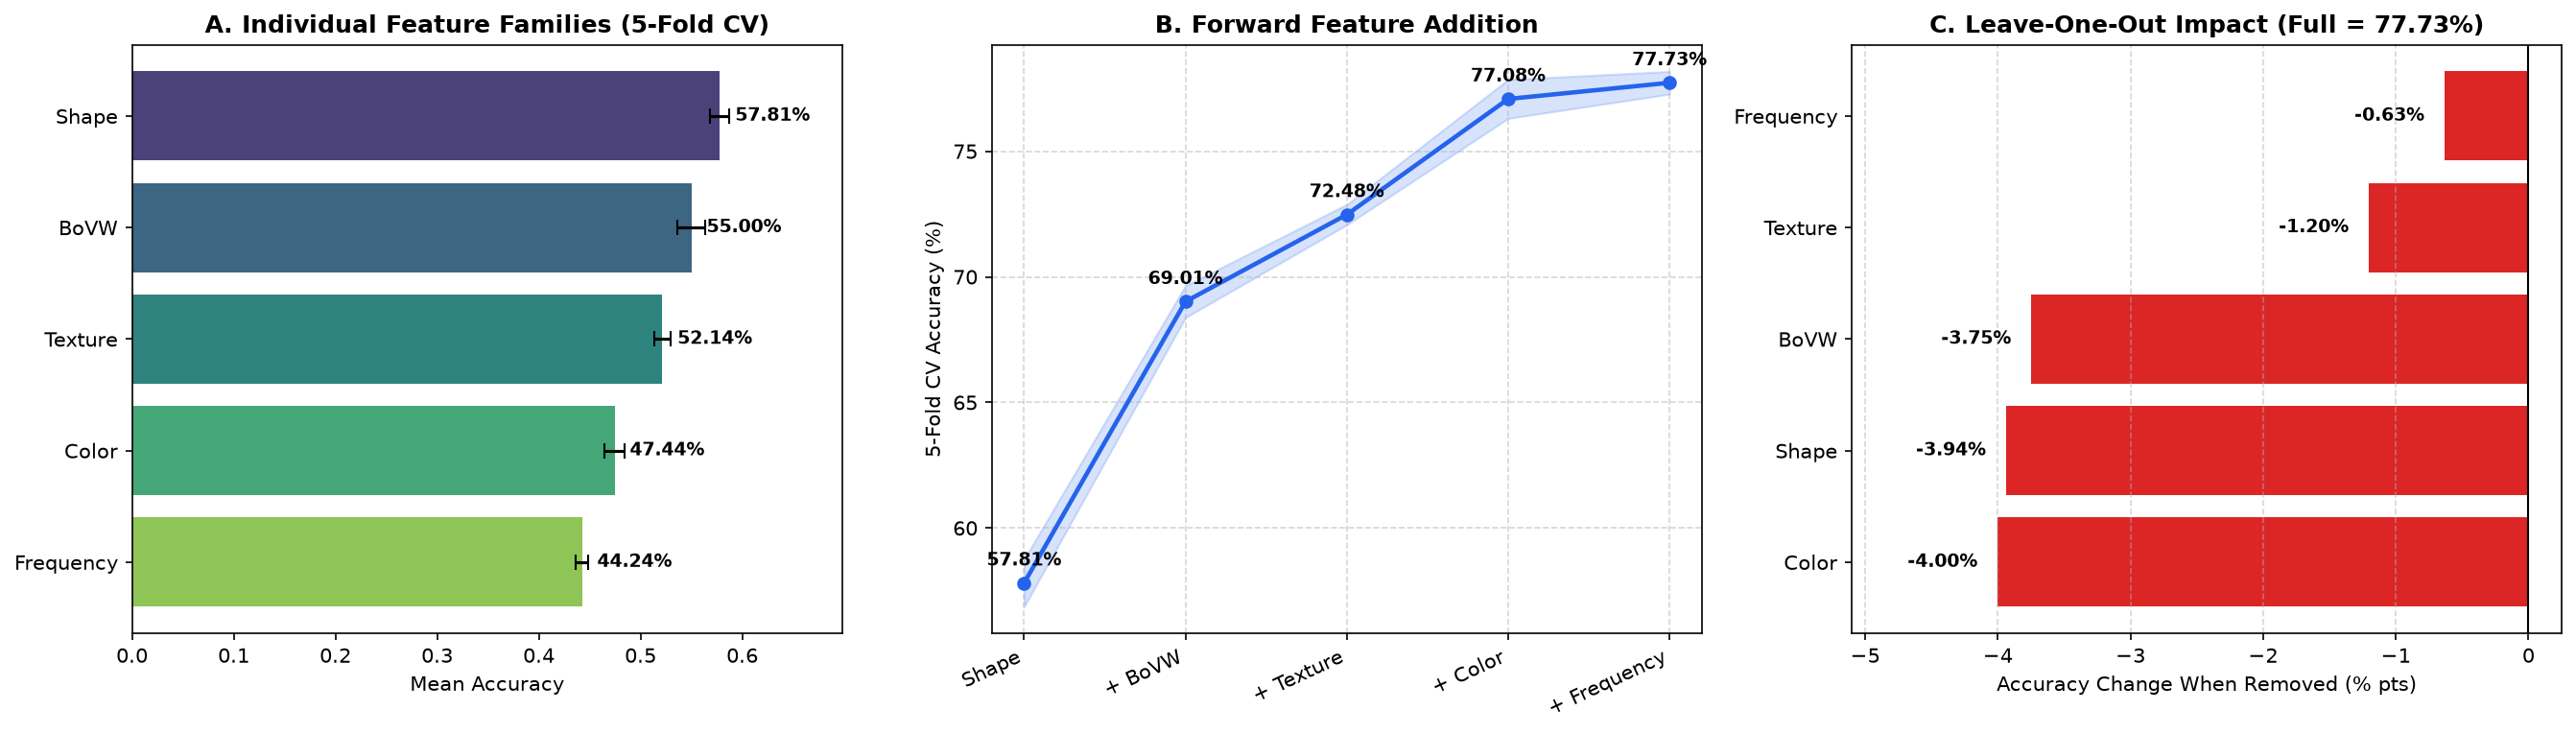

In [12]:
ALL_FAMILIES = list(TRAIN_FEATURES.keys())

# 1. Individual Family Performance
print("Running Part 1: Individual Feature Families...")
indiv_rows = []
for fam in ALL_FAMILIES:
    res = evaluate_feature_subset_cv([fam])
    res["family"] = fam
    indiv_rows.append(res)

indiv_df = pd.DataFrame(indiv_rows).sort_values("acc_mean", ascending=False).reset_index(drop=True)
display(indiv_df[["family", "n_dims", "acc_mean", "acc_std", "f1_mean", "cv_time_s"]])

# 2. Forward Addition (ranked by individual performance)
print("\nRunning Part 2: Forward Addition...")
ranked_families = indiv_df["family"].tolist()
fwd_rows = []
current_subset = []
for fam in ranked_families:
    current_subset.append(fam)
    res = evaluate_feature_subset_cv(current_subset)
    res["step"] = f"+ {fam}" if len(current_subset) > 1 else fam
    fwd_rows.append(res)

fwd_df = pd.DataFrame(fwd_rows)
display(fwd_df[["step", "families", "n_dims", "acc_mean", "acc_std", "f1_mean", "cv_time_s"]])

# 3. Leave-One-Out (LOO) from Full Fused Vector
print("\nRunning Part 3: Leave-One-Out (LOO)...")
full_acc = fwd_df.iloc[-1]["acc_mean"]
full_f1 = fwd_df.iloc[-1]["f1_mean"]

loo_rows = []
for fam in ALL_FAMILIES:
    subset = [f for f in ALL_FAMILIES if f != fam]
    res = evaluate_feature_subset_cv(subset)
    res["removed_family"] = fam
    res["delta_acc"] = res["acc_mean"] - full_acc  # Negative means accuracy dropped when removed
    res["delta_f1"] = res["f1_mean"] - full_f1
    loo_rows.append(res)

loo_df = pd.DataFrame(loo_rows).sort_values("delta_acc", ascending=True).reset_index(drop=True)
display(loo_df[["removed_family", "n_dims", "acc_mean", "delta_acc", "f1_mean", "delta_f1", "cv_time_s"]])

# --- Visualization (3-Panel Ablation Figure for Report) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=150)

# Panel A: Individual Families
sns.barplot(data=indiv_df, x="acc_mean", y="family", hue="family", palette="viridis", legend=False, ax=axes[0])
axes[0].errorbar(indiv_df["acc_mean"], range(len(indiv_df)), xerr=indiv_df["acc_std"], fmt="none", c="black", capsize=4)
axes[0].set_title("A. Individual Feature Families (5-Fold CV)", fontweight="bold")
axes[0].set_xlabel("Mean Accuracy")
axes[0].set_ylabel("")
axes[0].set_xlim(0, max(indiv_df["acc_mean"]) + 0.12)
for i, v in enumerate(indiv_df["acc_mean"]):
    axes[0].text(v + 0.015, i, f"{v*100:.2f}%", va="center", fontsize=9, fontweight="bold")

# Panel B: Forward Addition Curve
x_steps = range(len(fwd_df))
axes[1].plot(x_steps, fwd_df["acc_mean"] * 100, marker="o", linewidth=2.2, color="#2563EB")
axes[1].fill_between(
    x_steps,
    (fwd_df["acc_mean"] - fwd_df["acc_std"]) * 100,
    (fwd_df["acc_mean"] + fwd_df["acc_std"]) * 100,
    alpha=0.18, color="#2563EB"
)
axes[1].set_xticks(x_steps)
axes[1].set_xticklabels(fwd_df["step"], rotation=25, ha="right")
axes[1].set_title("B. Forward Feature Addition", fontweight="bold")
axes[1].set_ylabel("5-Fold CV Accuracy (%)")
axes[1].grid(True, linestyle="--", alpha=0.5)
for i, v in enumerate(fwd_df["acc_mean"] * 100):
    axes[1].text(i, v + 0.7, f"{v:.2f}%", ha="center", fontsize=9, fontweight="bold")

# Panel C: Leave-One-Out Delta Accuracy
colors_loo = ["#DC2626" if d < 0 else "#16A34A" for d in loo_df["delta_acc"]]
axes[2].barh(loo_df["removed_family"], loo_df["delta_acc"] * 100, color=colors_loo)
axes[2].axvline(0, color="black", linewidth=1.0)
axes[2].set_title(f"C. Leave-One-Out Impact (Full = {full_acc*100:.2f}%)", fontweight="bold")
axes[2].set_xlabel("Accuracy Change When Removed (% pts)")
axes[2].grid(axis="x", linestyle="--", alpha=0.5)
for i, d in enumerate(loo_df["delta_acc"] * 100):
    offset = -0.15 if d < 0 else 0.15
    ha = "right" if d < 0 else "left"
    axes[2].text(d + offset, i, f"{d:+.2f}%", va="center", ha=ha, fontsize=9, fontweight="bold")
    axes[2].set_xlim(min(loo_df["delta_acc"] * 100) - 1.1, 0.25)
plt.tight_layout()
os.makedirs("assets", exist_ok=True)
plt.savefig("assets/ablation_study.png", dpi=200, bbox_inches="tight")
plt.show()